# Chapter 3: ReAct Agents and Tool Calling

**ReAct** = **Rea**soning + **Act**ing. Instead of answering straight away, the LLM loops:

1. **Reason**: decide what it needs to know next.
2. **Act**: call a tool (web search, Wikipedia, your own function).
3. **Observe**: read the tool's result.
4. Repeat until it has enough to give a final answer.

This notebook:

| Step | What we do |
|------|------------|
| 1 | Create three tools: web search, Wikipedia, and a custom function |
| 2 | Build an agent with `create_agent` |
| 3 | Run it and watch the reason / act / observe loop |
| 4 | Compare a model with and without `bind_tools` |

**Setup:** put `OPENAI_API_KEY` in a `.env` file. The model is served from NVIDIA's OpenAI-compatible endpoint.

In [ ]:
# --- Setup: load the API key and create a plain chat model ---
from langchain_openai import ChatOpenAI
import os
from dotenv import load_dotenv

# Reads OPENAI_API_KEY (and anything else) from the local .env file
load_dotenv()

# Fail fast if the key is missing, instead of getting a confusing auth error later
if os.environ.get("OPENAI_API_KEY"):
    print("Key available")
else:
    raise ValueError("OPENAI_API_KEY not found")

from langchain_core.messages import HumanMessage,SystemMessage,AIMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser, PydanticOutputParser


# `llm` is used in the bind_tools demo at the end of the notebook.
# ChatOpenAI works with any OpenAI-compatible endpoint, here NVIDIA's.
llm = ChatOpenAI(
    base_url="https://integrate.api.nvidia.com/v1",
    # API key is read automatically from the OPENAI_API_KEY env var
    model="nvidia/nemotron-3.5-lightning-30b-a3b"
)

Key available


## Step 1: Define the tools

A tool is just a function plus a **name**, a **description** and an **input schema**. The LLM never sees the code, only those three things, so a clear description is what makes it pick the right tool.

Three ways to get a tool are shown below: two prebuilt community tools and one custom `@tool` function.

In [28]:
# TOOL - 1 [News Search Tool]
# A prebuilt LangChain tool that runs a web search through DuckDuckGo (no API key needed).

from langchain_community.tools import DuckDuckGoSearchRun
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper

search_tool = DuckDuckGoSearchRun(
    # The description is what the LLM reads to decide WHEN to call this tool
    description="This is a tool to search the web for news",
    # region="us-en": the default "wt-wt" makes the ddgs Wikipedia backend build the
    #   hostname wt.wikipedia.org, which fails with a DNS error.
    # time=None: the default "y" (past year) filter returns nothing when the LLM
    #   puts an old date in the query.
    api_wrapper=DuckDuckGoSearchAPIWrapper(region="us-en", backend="auto", time=None),
)

In [29]:
# TOOL - 2 [Wikipedia Search Tool]
# Prebuilt tool for factual / background lookups (people, places, concepts).

from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

# The api_wrapper does the actual HTTP calls; the tool wraps it so an LLM can call it
wikipedia_tool = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(),description="This is a tool to search Wikipedia")

In [30]:
# TOOL - 3 [Custom Enterprise Tool]
# Any Python function becomes a tool with the @tool decorator.

from langchain.tools import tool

@tool
def enterprise_tool(query:str)-> str:

    # The docstring is required: it becomes the tool description the LLM sees.
    # The type hints (query: str) become the tool's input schema.
    """This is a tool to send emails to employees"""

    # Stub: a real version would call your email / HR system here
    return "Email Sent"

### Combine into a toolkit

The agent receives the tools as a plain list.

In [31]:
# Collect every tool the agent may use; the LLM picks among them by name + description
ToolKit = [search_tool, wikipedia_tool, enterprise_tool]
ToolKit

[DuckDuckGoSearchRun(description='This is a tool to search the web for news', api_wrapper=DuckDuckGoSearchAPIWrapper(region='us-en', safesearch='moderate', time=None, max_results=5, backend='auto', source='text')),
 WikipediaQueryRun(description='This is a tool to search Wikipedia', api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from 'c:\\Users\\user\\Desktop\\Langchain-learning\\.venv\\Lib\\site-packages\\wikipedia\\__init__.py'>, top_k_results=3, lang='en', load_all_available_meta=False, doc_content_chars_max=4000)),
 StructuredTool(name='enterprise_tool', description='This is a tool to send emails to employees', args_schema=<class 'langchain_core.utils.pydantic.enterprise_tool'>, func=<function enterprise_tool at 0x00000216DEF520C0>)]

## Step 2: Create the agent

`create_agent` wires the model and tools into a LangGraph loop (model node <-> tool node).

Tool errors (rate limits, empty results, network issues) are common with free web search. The small middleware here turns an exception into a message the LLM can react to, rather than crashing the run.

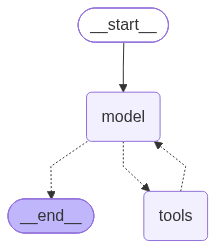

In [32]:
# --- Build the ReAct agent ---
# create_agent runs the loop: LLM reasons -> calls a tool -> reads the result -> repeats
# until it can answer.
from langchain.agents import create_agent
from langchain.agents.middleware import wrap_tool_call
from langchain_core.messages import ToolMessage
from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    base_url="https://integrate.api.nvidia.com/v1",
    model="nvidia/nemotron-3.5-lightning-30b-a3b",
    temperature=0.1,   # low = more deterministic tool choices
    max_tokens=1000,   # cap on the length of each reply
    timeout=30         # seconds before a model call is abandoned
)

# Middleware that wraps every tool call. Without it, one failed search (network,
# rate limit, no results) raises and kills the whole agent run.
@wrap_tool_call
def tool_errors_to_llm(request, handler):
    """Return tool exceptions to the LLM as a message instead of crashing the run."""
    try:
        return handler(request)
    except Exception as e:
        # The LLM sees this as the tool's output and can retry or answer without it
        return ToolMessage(
            content=f"Tool failed: {e}. Try a different query or answer without it.",
            tool_call_id=request.tool_call["id"],
        )

agent = create_agent(model, tools=ToolKit, middleware=[tool_errors_to_llm])
agent

## Step 3: Run the agent and watch the loop

Expected output order:

1. **Human Message**: your question
2. **AI Message** with `Tool Calls`: the *Act* step (which tool, with what arguments)
3. **Tool Message**: the *Observe* step (what the tool returned)
4. More tool calls if needed, then a final **AI Message** with the answer

If a tool call fails you will see the `Tool failed: ...` message and the model's next attempt.

In [33]:
# --- Run the agent ---
example_query = "Give me the latest news about the stock market"

# stream_mode="values" yields the full message list after every step of the loop
events = agent.stream(
    {"messages": [("user", example_query)]},
    stream_mode="values",
)
# Print only the newest message of each step: Human -> AI (tool call) -> Tool result -> AI answer
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

Give me the latest news about the stock market
================================== Ai Message ==================================
Tool Calls:
  duckduckgo_search (call-c9a6660f-bc7d-4cc2-9b9b-863e91bca0e1)
 Call ID: call-c9a6660f-bc7d-4cc2-9b9b-863e91bca0e1
  Args:
    query: latest stock market news
================================= Tool Message =================================
Name: duckduckgo_search

Get the latest news on the stock market and events that move stocks, with in-depth analyses to help you make investing and trading decisions. Find the latest stock market news from every corner of the globe at Reuters.com, your online source for breaking international market and finance news MarketWatch provides the latest stock market, financial and business news. Get stock market quotes, personal finance advice, company news and more. Share Market Today | Share Market Live updates: Get all the Latest Shar

## Step 4: What does `bind_tools` actually do?

The agent works because the model knows which tools exist. `bind_tools` is how that happens: it attaches the tool schemas to every request. Compare the two calls below.

In [34]:
# Without Binding
# The plain model has no idea tools exist, so it can only answer from training data
# (and typically says it has no live news access).
llm.invoke("What's the latest news about the stock market?")

AIMessage(content="I don't have access to live market data or real-time news feeds, and my training data has a fixed cutoff. I can't pull current stock prices, earnings reports, or today's market movements.\n\nFor the latest stock market news, I recommend checking:\n- **Financial websites:** Bloomberg, Reuters, CNBC, MarketWatch, or Yahoo Finance\n- **Brokerage platforms:** Most apps (Fidelity, Schwab, E*TRADE, Robinhood, etc.) provide real-time quotes, news, and analysis\n- **Market indices:** Checking the S&P 500, Dow Jones, and Nasdaq composite levels, plus sector performance\n- **Economic calendars:** For upcoming Fed meetings, CPI reports, or corporate earnings\n\nIf you'd like help understanding how to interpret market trends, what typically drives daily moves, or how to read key financial metrics, just let me know!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 686, 'prompt_tokens': 26, 'total_tokens': 712, 'completion_tokens_detai

In [35]:
# With Binding
# bind_tools sends the tool schemas along with the prompt. The model can now answer with a
# tool call (see .tool_calls on the result) instead of text.
# Note: it only REQUESTS the call. Nothing runs it; the agent loop above does that.
llm_binded = llm.bind_tools(ToolKit)
llm_binded.invoke("What's the latest news about the stock market?")

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 310, 'prompt_tokens': 437, 'total_tokens': 747, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 277, 'rejected_prediction_tokens': None, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'nvidia/nemotron-3.5-lightning-30b-a3b', 'system_fingerprint': None, 'id': 'chatcmpl-f3cb7dae-9f76-4883-bd29-a65585e2b91d', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a12f0c-19c5-7411-9866-74930baeee0f-0', tool_calls=[{'name': 'duckduckgo_search', 'args': {'query': 'latest stock market news'}, 'id': 'call-97fa0827-5010-4abc-889d-66175ee9b6e9', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 437, 'output_tokens': 310, 'total_toke

## Key takeaways

- A **tool** = function + name + description + input schema. The description drives tool selection.
- `bind_tools` only lets the model *request* a tool call; the **agent loop** executes it and feeds the result back.
- ReAct = repeat *reason -> act -> observe* until the model can answer.
- Real tools fail. Handle tool errors so one bad call does not end the run.